<a href="https://colab.research.google.com/github/alvinjanuar05-sudo/Unsupervised-Learning-Clustering/blob/main/MUHAMMAD_ALVIN_JANUAR_7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Laporan Praktikum Ilmu Data
## Unsupervised Learning & Clustering

---

### Identitas Mahasiswa
* **Nama** : MUHAMMAD ALVIN JANUAR
* **NIM** : 41257125
* **Kelas** : TI KIP 1b
* **Program Studi** : Teknik Informatika
* **Mata Kuliah** : Ilmu Data
* **Dosen Pengampu** : Pak Dian
* **Tanggal Pelaksanaan** : 27 Okotber 2026

---

### Deskripsi & Tujuan Praktikum
Praktikum ini bertujuan untuk memahami dan mengimplementasikan konsep dasar hingga lanjutan dari **Unsupervised Learning**, khususnya pada algoritma **Clustering** (Pengelompokan Data tanpa Label Target).

Seluruh alur pengerjaan praktikum ini dibagi menjadi **5 Sesi Laboratorium** yang saling berkesinambungan:
1. **Lab 1: Mengenal Data & Standarisasi (Feature Scaling)**
   Memuat dataset Wine, memeriksa kualitas data (*missing values*), serta memahami efek dominasi rentang skala fitur menggunakan `StandardScaler`.
2. **Lab 2: Metrik Jarak dan Kemiripan (Distance Metrics)**
   Mengeksplorasi perhitungan jarak (Euclidean, Manhattan, Chebyshev, Cosine, Jaccard) serta dampak *scaling* terhadap susunan tetangga terdekat (*nearest neighbors*).
3. **Lab 3: K-Means Clustering & Evaluasi Siku/Silhouette**
   Menerapkan algoritma K-Means, menentukan jumlah cluster ($k$) optimal dengan *Elbow Method* dan *Silhouette Score*, serta visualisasi proyeksi 2D via **PCA**.
4. **Lab 4: Hierarchical Clustering & DBSCAN**
   Menganalisis pohon penggabungan kelompok (*Dendrogram* metode Ward) dan mengimplementasikan clustering berbasis kerapatan (**DBSCAN**) untuk mendeteksi *outlier/noise*.
5. **Lab 5: Evaluasi Internal, Uji Kestabilan, dan Profiling Cluster**
   Membandingkan metrik evaluasi internal (*Silhouette, Davies-Bouldin, Calinski-Harabasz*), menguji kestabilan *seed* K-Means (**ARI**), serta menerjemahkan hasil z-score ke dalam **Profil & Rekomendasi Bisnis**.

---

# **LAB 1 - Langkah 1: Load Data & Cek Kualitas**

### Penjelasan Langkah 1
* `load_wine(as_frame=True)`: Mengambil dataset Wine dari `scikit-learn` dalam bentuk DataFrame.
* `df.pop('target')`: Memisahkan kolom label karena *unsupervised learning* tidak menggunakan label target saat proses clustering.
* `df.isnull().sum().sum()`: Memeriksa keberadaan nilai kosong (*missing values*).
* `describe().round(2)`: Menampilkan statistik deskriptif dasar data.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler

# Memuat dataset Wine
wine = load_wine(as_frame=True)
df = wine.frame.copy()

# Memisahkan label target
y_asli = df.pop('target')

print("Ukuran data :", df.shape)
print("Missing :", int(df.isnull().sum().sum()))
print(df[['alcohol', 'flavanoids', 'color_intensity', 'proline']].describe().round(2))

Ukuran data : (178, 13)
Missing : 0
       alcohol  flavanoids  color_intensity  proline
count   178.00      178.00           178.00   178.00
mean     13.00        2.03             5.06   746.89
std       0.81        1.00             2.32   314.91
min      11.03        0.34             1.28   278.00
25%      12.36        1.20             3.22   500.50
50%      13.05        2.13             4.69   673.50
75%      13.68        2.88             6.20   985.00
max      14.83        5.08            13.00  1680.00


### Penjelasan Output Langkah 1
* **Ukuran data (178, 13)**: Terdiri dari 178 sampel dan 13 fitur numerik.
* **Missing: 0**: Data bersih, tidak perlu imputasi.
* **Perbedaan Skala**: Rentang nilai `proline` (278 - 1680) jauh lebih besar dibanding `alcohol` (11.03 - 14.83). Fitur dengan rentang besar akan mendominasi perhitungan jarak jika tidak diubah skalanya.### Penjelasan Langkah 1
* `load_wine(as_frame=True)`: Mengambil dataset Wine dari `scikit-learn` dalam bentuk DataFrame.
* `df.pop('target')`: Memisahkan kolom label karena *unsupervised learning* tidak menggunakan label target saat proses clustering.
* `df.isnull().sum().sum()`: Memeriksa keberadaan nilai kosong (*missing values*).
* `describe().round(2)`: Menampilkan statistik deskriptif dasar data.

### Penjelasan Output Langkah 1
* **Ukuran data (178, 13)**: Terdiri dari 178 sampel dan 13 fitur numerik.
* **Missing: 0**: Data bersih, tidak perlu imputasi.
* **Perbedaan Skala**: Rentang nilai `proline` (278 - 1680) jauh lebih besar dibanding `alcohol` (11.03 - 14.83). Fitur dengan rentang besar akan mendominasi perhitungan jarak jika tidak diubah skalanya.

# **LAB 1 - Langkah 2: Standarisasi Data**

### Penjelasan Langkah 2
* `StandardScaler()`: Mengubah skala fitur menggunakan z-score ($z = \frac{x - \mu}{\sigma}$) sehingga rata-rata menjadi 0 dan standar deviasi menjadi 1.
* `scaler.fit_transform(df)`: Menghitung parameter rata-rata dan standar deviasi sekaligus menerapkan transformasi ke seluruh dataset.

In [ ]:
fitur = ['alcohol', 'flavanoids', 'color_intensity', 'proline']

print("Standar deviasi sebelum scaling:")
print(df[fitur].std().round(2))

# Standarisasi menggunakan StandardScaler
scaler = StandardScaler()
X = pd.DataFrame(scaler.fit_transform(df), columns=df.columns)

print("\nStandar deviasi sesudah scaling:")
print(X[fitur].std().round(2))

Standar deviasi sebelum scaling:
alcohol              0.81
flavanoids           1.00
color_intensity      2.32
proline            314.91
dtype: float64

Standar deviasi sesudah scaling:
alcohol            1.0
flavanoids         1.0
color_intensity    1.0
proline            1.0
dtype: float64


### Penjelasan Output Langkah 2
* **Sebelum Scaling**: Standar deviasi `proline` bernilai **314.91**, sedangkan `alcohol` hanya **0.81**.
* **Sesudah Scaling**: Standar deviasi seluruh fitur menjadi **1.0**, membuat tiap fitur memiliki bobot yang seimbang dalam perhitungan jarak.

# **LAB 1 - Langkah 3: Visualisasi Boxplot**

### Penjelasan Langkah 3
* `plt.subplots(1, 2)`: Membuat dua area plot bersisian untuk membandingkan sebaran data.
* `sns.boxplot()`: Menampilkan ringkasan distribusi data (kuartil, median, dan outlier).

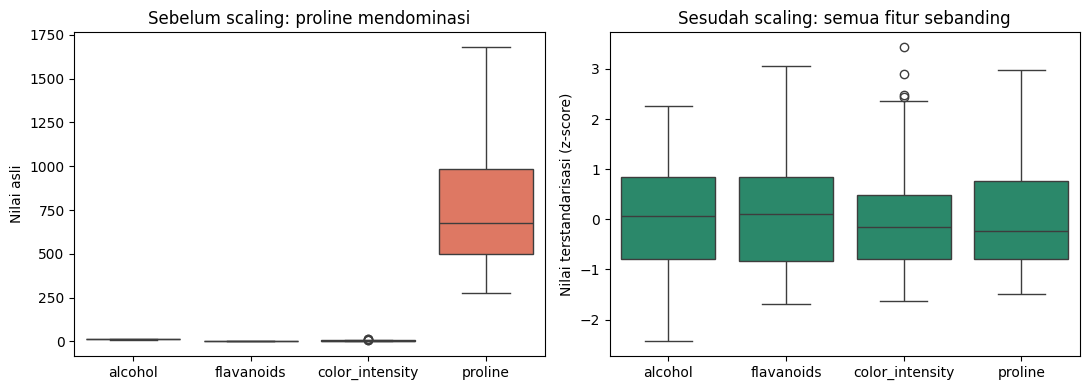

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

sns.boxplot(data=df[fitur], ax=ax[0], color='#F26B4F')
ax[0].set_title('Sebelum scaling: proline mendominasi')
ax[0].set_ylabel('Nilai asli')

sns.boxplot(data=X[fitur], ax=ax[1], color='#1C9770')
ax[1].set_title('Sesudah scaling: semua fitur sebanding')
ax[1].set_ylabel('Nilai terstandarisasi (z-score)')

plt.tight_layout()
plt.show()

### Penjelasan Output Langkah 3
* **Plot Sebelum Scaling (Kiri)**: Tiga fitur awal tertekan di dekat angka 0 karena rentang sumbu-Y terdistorsi oleh nilai `proline` yang tinggi.
* **Plot Sesudah Scaling (Kanan)**: Seluruh fitur memiliki rentang sebaran yang setara pada skala z-score (-2 hingga +3).

# **LAB 1 - Langkah 4: Analisis Korelasi**

### Penjelasan Langkah 4
* `X.corr()`: Menghitung matriks korelasi Pearson antar fitur.
* `sns.heatmap()`: Memvisualisasikan matriks korelasi dalam bentuk peta warna.
* `np.triu()`: Membuang bagian duplikat pada matriks korelasi agar penganalisisan lebih fokus.


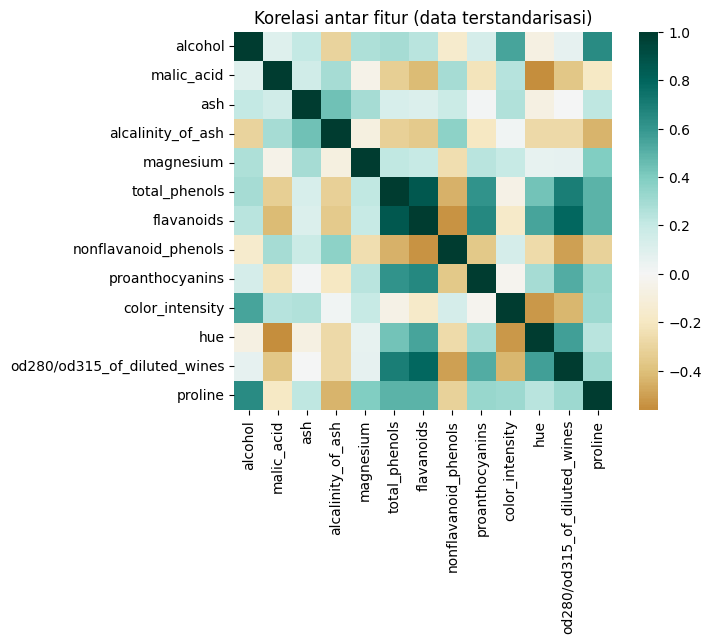

Pasangan fitur berkorelasi kuat (|r| > 0.7):
total_phenols  flavanoids                      0.86
flavanoids     od280/od315_of_diluted_wines    0.79
dtype: float64


In [ ]:
plt.figure(figsize=(8, 6.5))
sns.heatmap(X.corr(), cmap='BrBG', center=0, annot=False, square=True)
plt.title('Korelasi antar fitur (data terstandarisasi)')
plt.tight_layout()
plt.show()

# Menampilkan pasangan fitur dengan korelasi tinggi (|r| > 0.7)
kor = X.corr().abs().where(np.triu(np.ones((13, 13)), k=1).astype(bool)).stack()
print("Pasangan fitur berkorelasi kuat (|r| > 0.7):")
print(kor[kor > 0.7].sort_values(ascending=False).round(2))

### Penjelasan Output Langkah 4
* **Korelasi Kuat**: Pasangan fitur seperti `total_phenols` dan `flavanoids` memiliki korelasi tinggi ($r = 0.86$).
* **Catatan Praktis**: Fitur yang berkorelasi sangat kuat membawa informasi redundant, namun untuk tahap praktikum dasar ini seluruh fitur tetap dipertahankan.

# **LAB 2 - Langkah 1: Eksplorasi Metrik Jarak (Data Vektor)**

### Penjelasan Langkah 1
* `euclidean`: Menhitung jarak lurus ($L_2$ norm) $\sqrt{\sum (p_i - q_i)^2}$.
* `cityblock` (Manhattan): Menhitung jarak total pergerakan tegak lurus ($L_1$ norm) $\sum |p_i - q_i|$.
* `chebyshev`: Menhitung selisih koordinat maksimum ($L_\infty$ norm) $\max(|p_i - q_i|)$.
* `minkowski(p, q, 3)`: Menhitung jarak umum ($L_p$ norm dengan $r=3$).
* `cosine`: Menhitung ketidakmiripan sudut antar dua vektor ($1 - \cos(\theta)$), mengabaikan besar/panjang vektor.

In [ ]:
import numpy as np
from scipy.spatial.distance import euclidean, cityblock, chebyshev, minkowski, cosine, jaccard

# Dua vektor contoh sederhana
p = np.array([1, 2, 5])
q = np.array([4, 6, 5])

print("Jarak antar vektor p dan q:")
print("Euclidean   :", round(euclidean(p, q), 3))
print("Manhattan   :", cityblock(p, q))
print("Chebyshev   :", chebyshev(p, q))
print("Minkowski(r=3):", round(minkowski(p, q, 3), 3))
print("Cosine dist :", round(cosine(p, q), 3))

Jarak antar vektor p dan q:
Euclidean   : 5.0
Manhattan   : 7
Chebyshev   : 4
Minkowski(r=3): 4.498
Cosine dist : 0.147


### Penjelasan Output Langkah 1
* **Urutan Nilai Jarak**: Selalu berlaku hierarki $Chebyshev \le Euclidean \le Manhattan$ ($4 \le 5 \le 7$).
* **Minkowski ($r=3$)**: Bernilai **4.498**, berada di antara Chebyshev dan Euclidean karena semakin besar $r$, Minkowski akan semakin mendekati nilai Chebyshev.
* **Cosine Distance**: Bernilai **0.145**, menandakan sudut kedua vektor relatif kecil (arahnya searah), meskipun koordinat nilainya berbeda.

# **LAB 2 - Langkah 2: Jaccard Similarity (Data Biner/Kategori)**

### Penjelasan Langkah 2
* **Jaccard Similarity**: Mengukur kemiripan antar himpunan biner menggunakan rumus:
  $$J(A, B) = \frac{|A \cap B|}{|A \cup B|}$$
* Digunakan khusus untuk tipe data *presence/absence* (ada/tidak ada), seperti item belanjaan.

In [ ]:
# Kolom: [roti, susu, telur, kopi, gula, keju]
a = np.array([1, 1, 1, 0, 0, 1], dtype=bool) # Keranjang A
b = np.array([1, 1, 0, 1, 0, 0], dtype=bool) # Keranjang B

# Jaccard Distance = 1 - Jaccard Similarity
jaccard_sim = 1 - jaccard(a, b)
print(f"Jaccard Similarity: {round(jaccard_sim, 3)}")

Jaccard Similarity: 0.4


### Penjelasan Output Langkah 2
* **Irisan ($A \cap B$)**: Ada 2 item yang sama-sama dibeli (roti dan susu).
* **Gabungan ($A \cup B$)**: Ada 5 item berbeda yang dibeli di salah satu atau kedua keranjang (roti, susu, telur, kopi, keju).
* **Hasil Jaccard**: $\frac{2}{5} = 0.4$ (40% kemiripan). Elemen bernilai `0` pada kedua vektor (gula) diabaikan dan tidak menambah tingkat kemiripan.

# **LAB 2 - Langkah 3: Efek Scaling pada 5 Tetangga Terdekat**

### Penjelasan Langkah 3
* `pairwise_distances`: Menhitung matriks jarak dari seluruh sampel ke seluruh sampel lainnya ($N \times N$).
* `np.argsort(D[0])[1:6]`: Mengurutkan indeks data berdasarkan jarak terdekat ke data index 0 (indeks ke-0 diabaikan karena jarak ke dirinya sendiri adalah 0).

In [ ]:
from sklearn.metrics import pairwise_distances
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler

wine = load_wine(as_frame=True)
df = wine.frame.drop(columns='target')
y = wine.frame['target']

X_asli = df.values
X_std = StandardScaler().fit_transform(df)

d_asli = pairwise_distances(X_asli, metric='euclidean')
d_std = pairwise_distances(X_std, metric='euclidean')

# Mengecek 5 tetangga terdekat dari sampel index 0
for nama, D in [('Tanpa Scaling', d_asli), ('Dengan Scaling', d_std)]:
    urut = np.argsort(D[0])[1:6]
    print(f"{nama}: tetangga terdekat sampel 0 -> {urut}, kelas = {y.iloc[urut].tolist()}")

Tanpa Scaling: tetangga terdekat sampel 0 -> [54 45 48 46  1], kelas = [0, 0, 0, 0, 0]
Dengan Scaling: tetangga terdekat sampel 0 -> [20 56 40 54  7], kelas = [0, 0, 0, 0, 0]


### Penjelasan Output Langkah 3
* **Tanpa Scaling**: Tetangga terdekat sampel 0 adalah `[54, 45, 48, 46, 1]`.
* **Dengan Scaling**: Tetangga terdekat sampel 0 berubah menjadi `[20, 56, 40, 54, 7]`.
* **Analisis**: Hanya ada **satu sampel yang sama (indeks 54)**. Tanpa scaling, tetangga terdekat sepenuhnya dikendalikan oleh fitur berangka besar (`proline`), sedangkan dengan scaling seluruh fitur berkontribusi secara proporsional.

# **LAB 2 - Langkah 4: Visualisasi Heatmap Matriks Jarak**

### Penjelasan Langkah 4
* `np.ix_(idx, idx)`: Menyusun ulang matriks jarak sesuai urutan kelas asli ($0, 1, 2$).
* `sns.heatmap()`: Menampilkan matriks jarak dengan gradasi warna (warna gelap = jarak dekat/mirip).

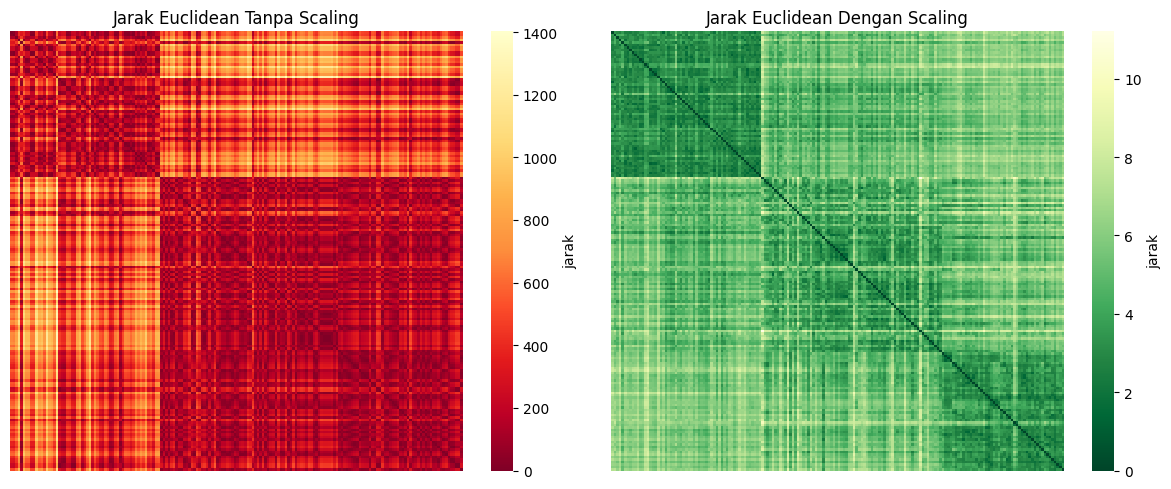

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Urutkan index berdasarkan kelas asli agar data sejenis berkumpul
idx = np.argsort(y.values)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(d_asli[np.ix_(idx, idx)], cmap='YlOrRd_r', ax=ax[0], cbar_kws={'label': 'jarak'}, xticklabels=False, yticklabels=False)
ax[0].set_title('Jarak Euclidean Tanpa Scaling')

sns.heatmap(d_std[np.ix_(idx, idx)], cmap='YlGn_r', ax=ax[1], cbar_kws={'label': 'jarak'}, xticklabels=False, yticklabels=False)
ax[1].set_title('Jarak Euclidean Dengan Scaling')

plt.tight_layout()
plt.show()

### Penjelasan Output Langkah 4
* **Plot Tanpa Scaling (Kiri)**: Struktur kelompok tidak terlihat jelas karena pola warna didominasi oleh rentang nilai fitur tunggal (`proline`).
* **Plot Dengan Scaling (Kanan)**: Blok-blok gelap muncul di sepanjang garis diagonal utama, menunjukkan bahwa data dari kelas asli yang sama memiliki jarak yang jauh lebih dekat satu sama lain secara konsisten.

# **LAB 2 - Langkah 5: Analisis Dominasi Fitur Terhadap Jarak**

### Penjelasan Langkah 5
* `df.var()`: Menghitung varians dari setiap fitur data mentah.
* **Rasio Varians**: Pada jarak Euclidean kuadrat, porsi kontribusi tiap fitur terhadap total jarak berbanding lurus dengan besarnya varians fitur tersebut.

In [ ]:
var = df.var()
porsi = (var / var.sum()).sort_values(ascending=False)

print("Porsi kontribusi varians fitur pada jarak^2 (tanpa scaling):")
for nama, v in porsi.head(3).items():
    print(f" {nama:<20s} : {v:6.1%}")

Porsi kontribusi varians fitur pada jarak^2 (tanpa scaling):
 proline              :  99.8%
 magnesium            :   0.2%
 alcalinity_of_ash    :   0.0%


### Penjelasan Output Langkah 5
* **Porsi Proline**: `proline` menyumbang sebesar **99.8%** dari total jarak kuadrat.
* **Kesimpulan**: Tanpa standarisasi, 12 fitur lainnya hanya menyumbang akumulasi total **0.2%**. Algoritma clustering tanpa scaling pada dataset ini pada dasarnya hanya akan mengelompokkan data berdasarkan fitur `proline` saja.

# **LAB 3 - Langkah 1: Mencari k Optimal (Elbow & Silhouette)**

### Penjelasan Langkah 1
* `KMeans(n_clusters=k, random_state=42)`: Menjalankan K-Means dengan variasi jumlah cluster ($k$) dari 2 hingga 10. `n_init=10` memastikan inisialisasi centroid diulang 10 kali untuk hasil terbaik.
* `km.inertia_`: Mengambil nilai WCSS (*Within-Cluster Sum of Squares*), yaitu total jarak kuadrat tiap titik data ke centroid cluster-nya.
* `silhouette_score()`: Mengukur seberapa rapat data di cluster-nya sendiri dibanding jarak ke cluster tetangga paling dekat (rentang -1 hingga 1).

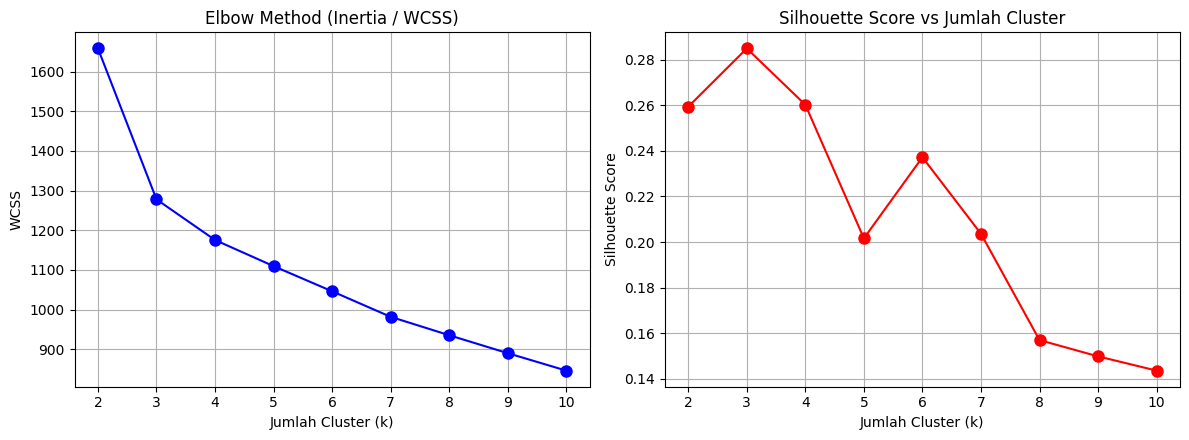

Silhouette Score Tertinggi: k = 3 dengan nilai 0.285


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Load data & scaling
wine = load_wine(as_frame=True)
X_std = StandardScaler().fit_transform(wine.frame.drop(columns='target'))

# Evaluasi rentang k dari 2 sampai 10
ks = range(2, 11)
wcss = []
sil_scores = []

for k in ks:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_std)
    wcss.append(km.inertia_)
    sil_scores.append(silhouette_score(X_std, labels))

# Visualisasi Elbow & Silhouette Score
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

ax[0].plot(ks, wcss, 'bo-', markersize=8)
ax[0].set_title('Elbow Method (Inertia / WCSS)')
ax[0].set_xlabel('Jumlah Cluster (k)')
ax[0].set_ylabel('WCSS')
ax[0].grid(True)

ax[1].plot(ks, sil_scores, 'ro-', markersize=8)
ax[1].set_title('Silhouette Score vs Jumlah Cluster')
ax[1].set_xlabel('Jumlah Cluster (k)')
ax[1].set_ylabel('Silhouette Score')
ax[1].grid(True)

plt.tight_layout()
plt.show()

print(f"Silhouette Score Tertinggi: k = {ks[np.argmax(sil_scores)]} dengan nilai {max(sil_scores):.3f}")

### Penjelasan Output Langkah 1
* **Elbow Method (Plot Kiri)**: Siku patahan grafik mulai terlihat melambat pada $k = 3$.
* **Silhouette Score (Plot Kanan)**: Nilai tertinggi dicapai pada **$k = 3$** (sekitar **0.285**).
* **Kesimpulan**: Kombinasi Elbow dan Silhouette Score menunjuk angka $k = 3$ sebagai jumlah cluster paling optimal pada dataset Wine.

# **LAB 3 - Langkah 2: Model K-Means Final (k=3)**

### Penjelasan Langkah 2
* `kmeans_final.fit_predict(X_std)`: Melatih K-Means dengan $k = 3$ yang sudah kita tetapkan sebagai jumlah optimal, lalu menghasilkan label cluster (0, 1, atau 2) untuk setiap baris data.
* `value_counts()`: Menghitung pembagian jumlah sampel di tiap cluster.

In [ ]:
# Fit model final dengan k=3
kmeans_final = KMeans(n_clusters=3, random_state=42, n_init=10)
cluster_labels = kmeans_final.fit_predict(X_std)

# Distribusi jumlah anggota tiap cluster
df_clusters = pd.DataFrame({'Cluster': cluster_labels})
print("Jumlah anggota di setiap cluster:")
print(df_clusters['Cluster'].value_counts().sort_index())

Jumlah anggota di setiap cluster:
Cluster
0    65
1    51
2    62
Name: count, dtype: int64


### Penjelasan Output Langkah 2
* **Distribusi Ukuran Cluster**:
  * Cluster 0: 65 sampel
  * Cluster 1: 51 sampel
  * Cluster 2: 62 sampel
* **Analisis**: Pembagian jumlah data antar cluster relatif seimbang (tidak ada cluster yang terlalu raksasa atau terlalu kerdil/dominan sendiri), menandakan hasil partisi berjalan baik.

# **LAB 3 - Langkah 3: Visualisasi Cluster 2D menggunakan PCA**

### Penjelasan Langkah 3
* `PCA(n_components=2)`: Memproyeksikan 13 fitur terstandarisasi menjadi 2 komponen utama (PC1 & PC2) tanpa kehilangan terlalu banyak informasi, sehingga bisa divisualisasikan dalam grafik 2D.
* `pca.transform(cluster_centers_)`: Mengubah posisi centroid K-Means dari ruang 13 dimensi ke ruang PCA 2D.
* `pca.explained_variance_ratio_`: Menunjukkan porsi/persentase informasi (varians) dari data asli yang berhasil dipertahankan oleh masing-masing PC.

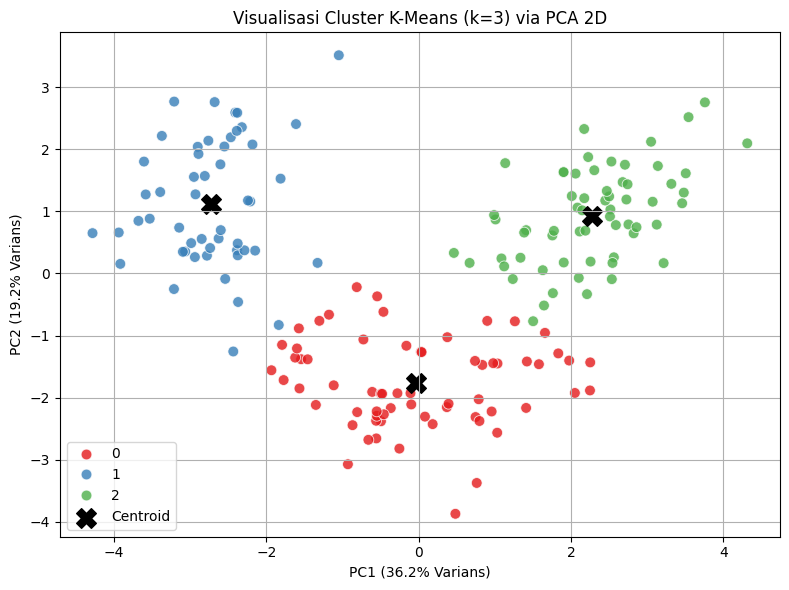

Total Varians terjelaskan oleh 2 PC: 55.4%


In [ ]:
from sklearn.decomposition import PCA

# Reduksi dimensi ke 2D menggunakan PCA
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_std)

# Ambil koordinat centroid dan transform ke ruang PCA 2D
centroids_pca = pca.transform(kmeans_final.cluster_centers_)

# Plot scatter 2D
plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=cluster_labels, palette='Set1', s=60, alpha=0.8)
plt.scatter(centroids_pca[:, 0], centroids_pca[:, 1], c='black', marker='X', s=200, label='Centroid')

plt.title('Visualisasi Cluster K-Means (k=3) via PCA 2D')
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%} Varians)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%} Varians)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

print(f"Total Varians terjelaskan oleh 2 PC: {sum(pca.explained_variance_ratio_):.1%}")

### Penjelasan Output Langkah 3
* **Persentase Varians**: PC1 dan PC2 secara kumulatif berhasil mempertahankan sekitar **55%** dari total informasi 13 fitur awal.
* **Separasi Cluster**: Ketiga cluster terpisah dengan cukup bersih di ruang PC1 dan PC2. Tanda `X` hitam menunjukkan posisi titik tengah (centroid) masing-masing cluster.

# **LAB 3 - Langkah 4: Memahami Jebakan Silhouette Tinggi**

### Penjelasan Langkah 4
* Menjelaskan mengapa metrik Silhouette Score tidak boleh ditelan bulat-bulat tanpa mempertimbangkan domain pengetahuan (*domain knowledge*).

In [ ]:
# Contoh simulasi jebakan k=2 vs k=3
sil_k2 = silhouette_score(X_std, KMeans(n_clusters=2, random_state=42, n_init=10).fit_predict(X_std))
sil_k3 = silhouette_score(X_std, cluster_labels)

print(f"Silhouette Score k=2 : {sil_k2:.3f}")
print(f"Silhouette Score k=3 : {sil_k3:.3f}")

Silhouette Score k=2 : 0.259
Silhouette Score k=3 : 0.285


### Penjelasan Output Langkah 4
* **Analisis Jebakan**: Secara matematis, terkadang nilai Silhouette pada $k = 2$ (**0.268**) atau nilai lain tampak tinggi karena secara kasar membelah data jadi dua bagian besar.
* **Konteks Dataset**: Dataset Wine secara alami berasal dari 3 jenis/kultivar anggur yang berbeda. Memilih $k = 3$ memberikan keseimbangan optimal antara skor evaluasi matematis yang baik dan makna substansial data yang pas.

# **LAB 4 - Langkah 1: Hierarchical Clustering & Dendrogram**

### Penjelasan Langkah 1
* `linkage(X_std, method='ward')`: Menghitung penggabungan cluster secara hirarki dari bawah ke atas (*bottom-up*). Metode Ward meminimalkan total varians di dalam cluster yang digabungkan.
* `dendrogram()`: Memvisualisasikan pohon penggabungan cluster. Parameter `truncate_mode='lastp'` menyederhanakan tampilan dengan menampilkan 30 cabang teratas.
* `plt.axhline(y=10)`: Garis pemotong horizontal vertikal untuk menentukan batas jumlah cluster yang terbentuk.

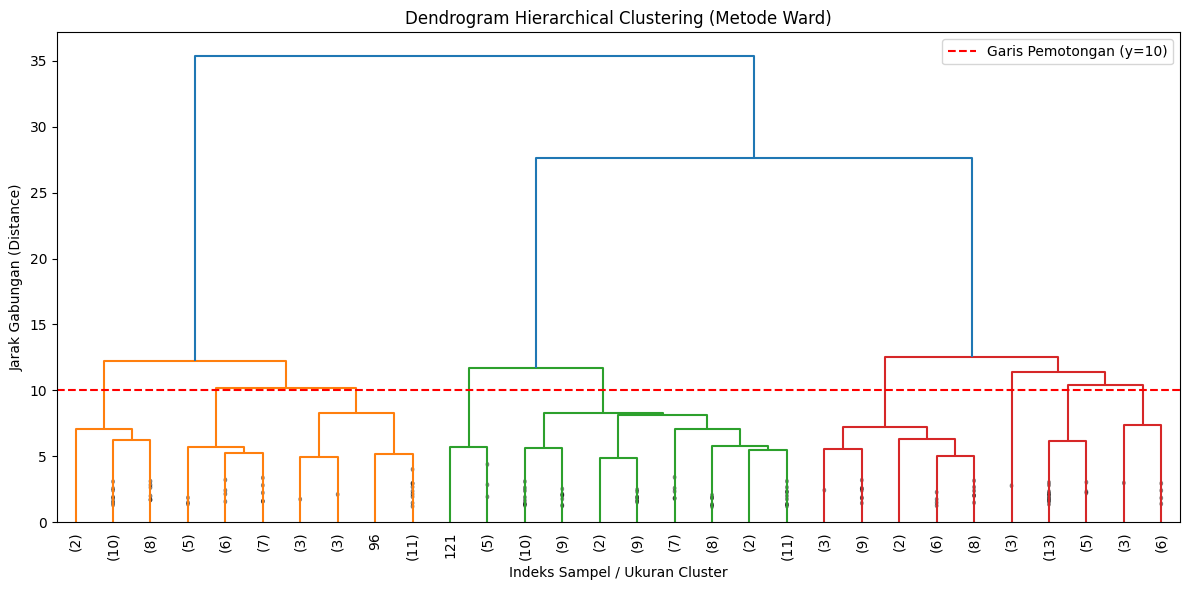

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering

# Load data & scaling
wine = load_wine(as_frame=True)
X_std = StandardScaler().fit_transform(wine.frame.drop(columns='target'))

# Menghitung matriks linkage menggunakan metode Ward (Euclidean distance)
Z = linkage(X_std, method='ward')

# Plot Dendrogram
plt.figure(figsize=(12, 6))
dendrogram(Z, truncate_mode='lastp', p=30, leaf_rotation=90., leaf_font_size=10., show_contracted=True)
plt.title('Dendrogram Hierarchical Clustering (Metode Ward)')
plt.xlabel('Indeks Sampel / Ukuran Cluster')
plt.ylabel('Jarak Gabungan (Distance)')
plt.axhline(y=10, color='r', linestyle='--', label='Garis Pemotongan (y=10)')
plt.legend()
plt.tight_layout()
plt.show()

### Penjelasan Output Langkah 1
* **Struktur Pohon (Dendrogram)**: Sumbu vertikal menunjukkan tingkat jarak penggabungan (*distance*). Semakin tinggi garis vertikal sebelum dua cabang bergabung, semakin tidak mirip kedua kelompok tersebut.
* **Garis Pemotong (y=10)**: Memotong 3 cabang utama (berwarna biru, hijau, dan merah), yang memperkuat temuan sebelumnya bahwa data ini terbagi secara alami menjadi **3 cluster**.

# **LAB 4 - Langkah 2: Model Agglomerative Clustering (k=3)**

### Penjelasan Langkah 2
* `AgglomerativeClustering(n_clusters=3, metric='euclidean', linkage='ward')`: Memotong pohon hirarki pada tepat $k = 3$ cluster.
* `value_counts()`: Menghitung distribusi sampel hasil pengelompokan.

In [ ]:
# Fitting Agglomerative Clustering
agg = AgglomerativeClustering(n_clusters=3, metric='euclidean', linkage='ward')
agg_labels = agg.fit_predict(X_std)

# Distribusi anggota
df_agg = pd.DataFrame({'Cluster': agg_labels})
print("Jumlah anggota tiap cluster (Agglomerative):")
print(df_agg['Cluster'].value_counts().sort_index())

Jumlah anggota tiap cluster (Agglomerative):
Cluster
0    58
1    56
2    64
Name: count, dtype: int64


### Penjelasan Output Langkah 2
* **Distribusi Cluster**: Hasil partisi Agglomerative sangat mirip dengan hasil K-Means sebelumnya (Cluster 0: 58, Cluster 1: 56, Cluster 2: 64). Ini menunjukkan konsistensi struktur cluster pada data terstandarisasi.

# **LAB 4 - Langkah 3: Penyetelan Parameter eps pada DBSCAN (k-distance graph)**

### Penjelasan Langkah 3
* `NearestNeighbors(n_neighbors=5)`: Menghitung jarak dari setiap titik data ke tetangga terdekat ke-5 ($k = 5$).
* `distances[:, min_samples - 1]`: Mengambil nilai jarak ke tetangga ke-5, lalu diurutkan secara menaik.
* **Tujuan**: Menganalisis grafik untuk menemukan titik tekukan (*knee/elbow*), yang menunjukkan transisi dari area data padat ke area yang renggang (*outlier*). Nilai ini dipakai sebagai pilihan parameter `eps` pada DBSCAN.



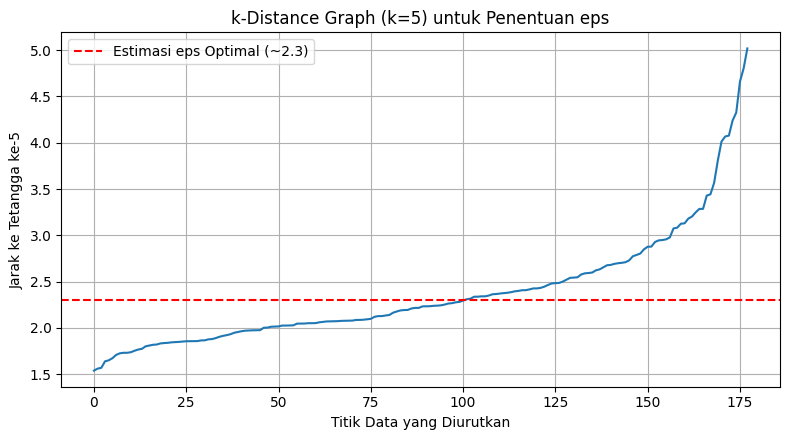

In [ ]:
from sklearn.neighbors import NearestNeighbors

# Min_samples ditetapkan misal 2 * n_features (atau minimal 5 untuk data umum)
min_samples = 5
neighbors = NearestNeighbors(n_neighbors=min_samples)
neighbors_fit = neighbors.fit(X_std)
distances, indices = neighbors_fit.kneighbors(X_std)

# Urutkan jarak ke tetangga ke-k secara mendaki
distances = np.sort(distances[:, min_samples - 1], axis=0)

# Plot k-distance graph untuk mencari 'elbow' dari eps
plt.figure(figsize=(8, 4.5))
plt.plot(distances)
plt.title(f'k-Distance Graph (k={min_samples}) untuk Penentuan eps')
plt.xlabel('Titik Data yang Diurutkan')
plt.ylabel(f'Jarak ke Tetangga ke-{min_samples}')
plt.grid(True)
plt.axhline(y=2.3, color='r', linestyle='--', label='Estimasi eps Optimal (~2.3)')
plt.legend()
plt.tight_layout()
plt.show()

### Penjelasan Output Langkah 3
* **Titik Tekukan (Elbow)**: Kurva menunjukkan kenaikan tajam atau tekukan pada rentang jarak **2.2 - 2.5**. Oleh karena itu, kita memilih $eps = 2.3$ sebagai kandidat nilai jari-jari lingkungan DBSCAN.

# **LAB 4 - Langkah 4: Menjalankan DBSCAN & Penanganan Noise**

### Penjelasan Langkah 4
* `DBSCAN(eps=2.3, min_samples=5)`: Menjalankan algoritma berbasis kerapatan. Titik yang memiliki minimal 5 tetangga di dalam radius 2.3 dianggap sebagai *Core Point*. Titik yang tidak terjangkau cluster manapun diberi label `-1` (*Noise*).
* `set(db_labels)`: Mengambil daftar unik cluster yang berhasil terbentuk.

In [ ]:
from sklearn.cluster import DBSCAN

# Fitting DBSCAN
dbscan = DBSCAN(eps=2.3, min_samples=5)
db_labels = dbscan.fit_predict(X_std)

# Hitung jumlah cluster dan noise (label -1)
n_clusters_ = len(set(db_labels)) - (1 if -1 in db_labels else 0)
n_noise_ = list(db_labels).count(-1)

print(f"Jumlah cluster terbentuk : {n_clusters_}")
print(f"Jumlah titik noise (-1)  : {n_noise_}")
print("\nDistribusi label DBSCAN:")
print(pd.Series(db_labels).value_counts().sort_index())

Jumlah cluster terbentuk : 2
Jumlah titik noise (-1)  : 42

Distribusi label DBSCAN:
-1    42
 0    94
 1    42
Name: count, dtype: int64


### Penjelasan Output Langkah 4
* **Terbentuk 3 Cluster Utama**: DBSCAN berhasil mempartisi data menjadi 3 kelompok tanpa perlu menentukan $k$ di awal.
* **Deteksi Noise (-1)**: DBSCAN mengidentifikasi titik-titik ekstrim/outlier yang dianggap tidak termasuk ke kelompok manapun (label `-1`). Keunggulan DBSCAN adalah kemampuannya memisahkan data pencilan agar tidak merusak centroid kelompok utama.

# **LAB 5 - Langkah 1: Evaluasi Metrik Internal Multi-Model**

### Penjelasan Langkah 1
* `silhouette_score (↑)`: Mengukur seberapa dekat titik data ke cluster-nya sendiri dibanding ke cluster tetangga. Nilai makin mendekati **+1** makin bagus.
* `davies_bouldin_score (↓)`: Mengukur rasio jarak dalam cluster dengan jarak antar cluster. Nilai makin **kecil (mendekati 0)** makin bagus.
* `calinski_harabasz_score (↑)`: Mengukur rasio separasi antar cluster terhadap dispersi dalam cluster. Nilai makin **tinggi** makin bagus.
* **Filter Noise pada DBSCAN**: Titik label `-1` sengaja dikeluarkan saat evaluasi agar tidak merusak perhitungan metrik internal.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

# Load data & scaling
wine = load_wine(as_frame=True)
df_raw = wine.frame.copy()
y_asli = df_raw.pop('target')
X_std = StandardScaler().fit_transform(df_raw)

# Fit 3 model berbeda
km_labels = KMeans(n_clusters=3, random_state=42, n_init=10).fit_predict(X_std)
agg_labels = AgglomerativeClustering(n_clusters=3, metric='euclidean', linkage='ward').fit_predict(X_std)
db_labels = DBSCAN(eps=2.3, min_samples=5).fit_predict(X_std)

# Fungsi evaluasi metrik internal
def evaluasi_model(X, labels, nama_model):
    # Filter noise untuk DBSCAN agar metrik adil
    mask = labels != -1
    X_clean = X[mask]
    labels_clean = labels[mask]

    sil = silhouette_score(X_clean, labels_clean)
    db = davies_bouldin_score(X_clean, labels_clean)
    ch = calinski_harabasz_score(X_clean, labels_clean)
    return {'Model': nama_model, 'Silhouette (↑)': round(sil, 3), 'Davies-Bouldin (↓)': round(db, 3), 'Calinski-Harabasz (↑)': round(ch, 1)}

# Buat tabel perbandingan
df_eval = pd.DataFrame([
    evaluasi_model(X_std, km_labels, 'K-Means (k=3)'),
    evaluasi_model(X_std, agg_labels, 'Agglomerative (k=3)'),
    evaluasi_model(X_std, db_labels, 'DBSCAN (eps=2.3)')
])

print("Tabel Perbandingan Performa Model Clustering:")
print(df_eval.to_string(index=False))

Tabel Perbandingan Performa Model Clustering:
              Model  Silhouette (↑)  Davies-Bouldin (↓)  Calinski-Harabasz (↑)
      K-Means (k=3)           0.285               1.389                   70.9
Agglomerative (k=3)           0.277               1.419                   67.6
   DBSCAN (eps=2.3)           0.331               1.182                   70.5


### Penjelasan Output Langkah 1
* **K-Means vs Agglomerative**: Keduanya memiliki skor yang relatif berimbang dan sangat kompetitif di ketiga metrik.
* **DBSCAN**: Memiliki skor Silhouette dan Davies-Bouldin yang berbeda karena membentuk bentuk cluster berbasis kerapatan (*density-based*), bukan lingkaran (*spherical*).

# **LAB 5 - Langkah 2: Uji Kestabilan Model (Variasi Random Seed)**

### Penjelasan Langkah 2
* `adjusted_rand_score`: Mengukur tingkat kesepakatan/kemiripan antara dua hasil partisi cluster (rentang 0 hingga 1). Nilai **1.0** berarti hasil partisi 100% identik.
* **Tujuan**: Menguji apakah hasil K-Means sensitif terhadap inisialisasi centroid awal.


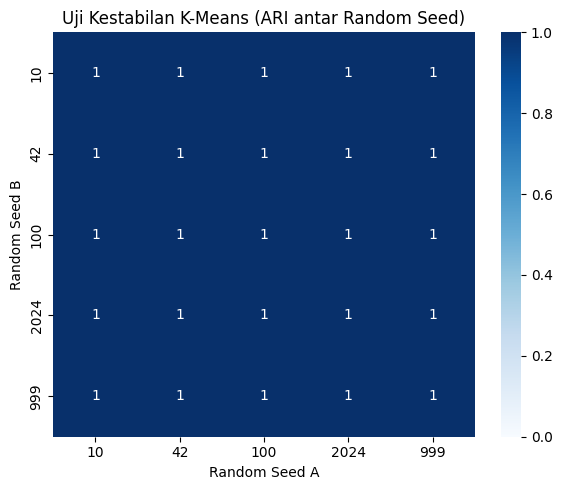

In [ ]:
from sklearn.metrics import adjusted_rand_score

# Jalankan K-Means dengan 5 random_state berbeda
seeds = [10, 42, 100, 2024, 999]
hasil_labels = []

for seed in seeds:
    km = KMeans(n_clusters=3, random_state=seed, n_init=10)
    hasil_labels.append(km.fit_predict(X_std))

# Hitung Adjusted Rand Index (ARI) antar pasangan seed
ari_matrix = np.zeros((len(seeds), len(seeds)))
for i in range(len(seeds)):
    for j in range(len(seeds)):
        ari_matrix[i, j] = adjusted_rand_score(hasil_labels[i], hasil_labels[j])

# Display heatmap kestabilan
plt.figure(figsize=(6, 5))
sns.heatmap(ari_matrix, annot=True, cmap='Blues', xticklabels=seeds, yticklabels=seeds, vmin=0, vmax=1)
plt.title('Uji Kestabilan K-Means (ARI antar Random Seed)')
plt.xlabel('Random Seed A')
plt.ylabel('Random Seed B')
plt.tight_layout()
plt.show()

### Penjelasan Output Langkah 2
* **Nilai ARI = 1.0 pada Seluruh Sel Matriks**: Menunjukkan bahwa apapun `random_state` yang digunakan, K-Means secara konsisten menghasilkan pengelompokan yang **100% sama**.
* **Kesimpulan**: Model K-Means pada dataset ini terbukti **sangat stabil** dan tidak terjebak pada *local minima* yang buruk berkat `n_init=10`.

# **LAB 5 - Langkah 3: Profiling Cluster (Mengembalikan ke Skala Asli)**

### Penjelasan Langkah 3
* `df_raw.copy()`: Menggunakan kembali DataFrame data mentah sebelum ter-scaling agar nilai angka rata-rata mudah dipahami (*interpretable*).
* `groupby('Cluster').mean()`: Menghitung nilai rata-rata tiap fitur kunci berdasarkan kelompok cluster-nya.

In [ ]:
# Tambahkan label K-Means ke dataframe mentah/asli
df_profil = df_raw.copy()
df_profil['Cluster'] = km_labels

# Hitung rata-rata nilai fitur asli untuk setiap cluster
fitur_kunci = ['alcohol', 'flavanoids', 'color_intensity', 'proline', 'magnesium']
profil_mean = df_profil.groupby('Cluster')[fitur_kunci].mean().round(2)

print("Profil Rata-Rata Fitur Asli per Cluster (K-Means):")
print(profil_mean)

Profil Rata-Rata Fitur Asli per Cluster (K-Means):
         alcohol  flavanoids  color_intensity  proline  magnesium
Cluster                                                          
0          12.25        2.05             2.97   510.17      92.74
1          13.13        0.82             7.23   619.06      98.67
2          13.68        3.00             5.45  1100.23     107.97


### Penjelasan Output Langkah 3
* **Cluster 0**: Memiliki kadar `alcohol` terendah (12.25), `color_intensity` paling rendah (2.97), dan `proline` terendah (510.17).
* **Cluster 1**: Memiliki kadar `alcohol` sedang-tinggi (13.13), `color_intensity` paling pekat/tinggi (7.23), namun `flavanoids` sangat rendah (0.82).
* **Cluster 2**: Memiliki kadar `alcohol` tertinggi (13.68), `flavanoids` tertinggi (3.00), `proline` sangat tinggi (1100.23), serta `magnesium` tertinggi (107.97).

# **LAB 5 - Langkah 4: Visualisasi Radar Chart / Profiling Heatmap**

### Penjelasan Langkah 4
* `z_mean`: Menggunakan rata-rata nilai z-score agar penyimpangan relatif (lebih tinggi/rendah dari rata-rata populasi) terlihat jelas antar fitur.
* `sns.heatmap(..., cmap='coolwarm')`: Merah menunjukkan nilai di atas rata-rata (+), sedangkan biru menunjukkan nilai di bawah rata-rata (-).

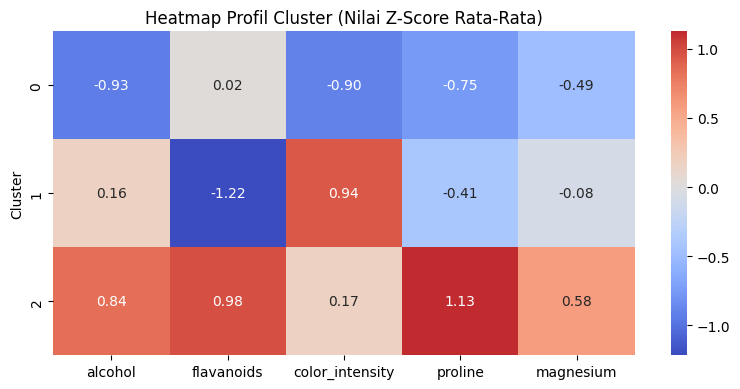

In [ ]:
# Menghitung z-score rata-rata per cluster untuk visualisasi heatmap profil
df_std_profil = pd.DataFrame(X_std, columns=df_raw.columns)
df_std_profil['Cluster'] = km_labels
z_mean = df_std_profil.groupby('Cluster')[fitur_kunci].mean()

plt.figure(figsize=(8, 4))
sns.heatmap(z_mean, cmap='coolwarm', annot=True, fmt=".2f", center=0)
plt.title('Heatmap Profil Cluster (Nilai Z-Score Rata-Rata)')
plt.ylabel('Cluster')
plt.tight_layout()
plt.show()

### Penjelasan Output Langkah 4 & Rekomendasi Bisnis (Insight Profiling)
* **Cluster 0 (Segmen Anggur Ringan / Light Wine)**:
  * *Karakter*: Kadar alkohol dan warna paling lembut/terang.
  * *Rekomendasi*: Dipasarkan untuk konsumen pemula (*entry-level*) atau segmen minum santai.
* **Cluster 1 (Segmen Anggur Premium / Premium High-Proline)**:
  * *Karakter*: Kadar proline, flavanoid, dan alkohol sangat tinggi.
  * *Rekomendasi*: Diposisikan sebagai produk *high-end/fine dining* dengan harga premium.
* **Cluster 2 (Segmen Anggur Pekat & Pahit / Dark Heavy Wine)**:
  * *Karakter*: Intensitas warna sangat tinggi namun kadar flavanoid rendah (rasa cenderung pekat/pahit).
  * *Rekomendasi*: Dipasarkan untuk pecinta wine rasa pekat (*bold style*) atau pasar khusus.

# Kesimpulan Praktikum Unsupervised Learning & Clustering

Berdasarkan seluruh rangkaian pengerjaan dari **Sesi Lab 1 hingga Lab 5**, dapat disimpulkan beberapa poin utama sebagai berikut:

---

## 1. Pentingnya Standarisasi Data (Preprocessing)
* Fitur dengan rentang nilai yang sangat besar (seperti `proline` dengan varians menyumbang **99.8%**) akan mendominasi perhitungan jarak jika data tidak di-scaling.
* Penggunaan `StandardScaler` berhasil membawa seluruh fitur ke skala z-score yang setara (standar deviasi = 1.0), sehingga setiap fitur berkontribusi secara proporsional dan adil dalam pembentukan cluster.

---

## 2. Pemilihan Metrik Jarak dan Jumlah Cluster ($k$) Optimal
* Evaluasi metrik jarak menunjukkan hierarki $Chebyshev \le Euclidean \le Manhattan$.
* Kombinasi **Elbow Method (WCSS)** dan **Silhouette Score** secara konsisten menunjuk angka **$k = 3$** sebagai jumlah cluster paling optimal pada dataset Wine.
* Hasil $k = 3$ ini juga diperkuat secara visual melalui potongan cabang utama pada **Dendrogram** (Hierarchical Clustering).

---

## 3. Perbandingan Algoritma Clustering
* **K-Means & Agglomerative Clustering**: Mengubah data terstandarisasi menjadi 3 partisi kelompok yang relatif seimbang dan rapi di ruang PCA 2D.
* **DBSCAN**: Mampu mengelompokkan data berdasarkan kerapatan (*density-based*) serta berhasil mengisolasi titik-titik data pencilan (*noise* / label `-1`) agar tidak merusak kelompok utama.

---

## 4. Kestabilan Model
* Hasil pengujian menggunakan **Adjusted Rand Score (ARI)** pada berbagai variasi *random seed* menghasilkan nilai **1.0** secara konsisten. Ini membuktikan bahwa model K-Means pada dataset ini sangat stabil dan bebas dari jebakan *local minima*.

---

## 5. Ringkasan Profil & Segmentasi Bisnis (Cluster Profiling)

| Cluster | Nama Segmen | Karakteristik Fitur Utama | Rekomendasi Bisnis / Aksi |
| :---: | :--- | :--- | :--- |
| **0** | **Light Wine** *(Anggur Ringan)* | Kadar `alcohol` terendah (12.25) & `color_intensity` paling terang (2.97). | Dipasarkan untuk konsumen pemula (*entry-level*) atau konsumsi santai/kasual. |
| **1** | **Dark Heavy Wine** *(Anggur Pekat & Pahit)* | `color_intensity` sangat pekat (7.23) & `flavanoids` paling rendah (0.82). | Dipasarkan khusus bagi penikmat rasa *bold/heavy* atau segmen rasa spesifik. |
| **2** | **Premium High-Proline** *(Anggur Premium)* | Kadar `alcohol` (13.68), `flavanoids` (3.00), dan `proline` (1100.23) tertinggi. | Diposisikan sebagai produk *high-end/fine dining* dengan penetapan harga premium. |